In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings("ignore")

<h1><b>Introduction</b></h1>

<p>All creatures of the earth were born from nature, from the algae in the oceans to the river reeds, from the elephants in the savanna to the pigeons that dominate urban environments, and the most dominant creature of them all, humans. Nature affects humanity in every way, and humanity affects nature in return. This project examines data on the most pressing way humanity has affected nature: climate change, as well as data on animals and their conservation status.</p>
<p>This section of work observes the relationship between rising global temperatures and conservation status.</p>

In [2]:
temp_data = pd.read_csv("temperature-medie-annuali-1950-2024.csv")
animal_data = pd.read_csv("Animal Dataset.csv")

In [ ]:
#converted to Farenheit just for my own personal preference, but can be changed back to Celsius if needed
temp_data['mean_temperature'] = (temp_data['mean_temperature'] * 1.8) + 32

<h1><b>Merging Animal and Temperature Data</b></h1>

In [4]:

# Give each animal one row per listed place
animal_by_country = animal_data.assign(
    country=animal_data["Countries Found"].str.split(",")
).explode("country")
animal_by_country["country"] = animal_by_country["country"].str.strip()

# Keeping rows where the country in both datasets match
merged = animal_by_country.merge(temp_data, on="country", how="inner")

merged[["Animal", "country", "Conservation Status", "year", "mean_temperature"]].head()

,Animal,country,Conservation Status,year,mean_temperature
0,Australian Fur Seal,Australia,Least Concern,1950,69.872
1,Australian Fur Seal,Australia,Least Concern,1951,70.106
2,Australian Fur Seal,Australia,Least Concern,1952,70.142
3,Australian Fur Seal,Australia,Least Concern,1953,70.124
4,Australian Fur Seal,Australia,Least Concern,1954,70.250


In [5]:
merged.shape[0]

5475

In [6]:
merged['Conservation Status'] = merged['Conservation Status'].replace({'Not Applicable': 'Least Concern', 'Not Evaluated': 'Least Concern', 'Data Deficient': 'Least Concern', 'Vulnerable': 'Endangered', 'Critically Endangered': 'Endangered', 'Near Threatened':'Endangered', 'Extinct (around 58 million years ago)': 'Extinct', 'Varies':'Least Concern'})

<p>
When examining the relationship between Conservation Status and Rising Temperatures, there was a notable association. Species with a Conservation Status of Endangered or Extinct tended to be more present in countries with higher average temperatures, while Least Concern species were more common in countries with much lower average temperatures. While this does not necessarily indicate causation or provide true evidence of a strong correlation between the rise of Endangered species and Rising Temperatures or Carbon Dioxide Emissions, this is an interesting finding and does indicate prior research done in <i>Endangered and Threatened Species and Global Warming</i> has a basis in its stance on the endangerment and extinction of species rising along with the temperature of the planet.
</p>

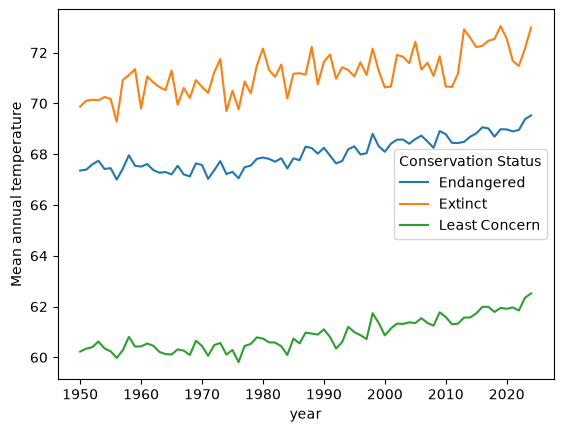

In [7]:
# Count each country once per year and status, even if several listed animals share it
trend = (
    merged.drop_duplicates(["country", "year", "Conservation Status"])
    .groupby(["year", "Conservation Status"], as_index=False)["mean_temperature"]
    .mean()
)
sns.lineplot(data=trend, x="year", y="mean_temperature", hue="Conservation Status")
plt.ylabel("Mean annual temperature")
plt.show()

<p>The graph shows that endangered and extinct species tended to be more present in areas with higher average temperatures, while species of least concern were in areas with lower rising temperatures. This does display that there is some association between rising temperatures and some endangered species; however, this is not evidence of causation and, to a degree, does not reflect the prior research due to species in colder climates still facing issues of endangerment and extinction as well, such as the polar bear and caribou. However, this trend is still worth considering alongside the rise in endangered species and rising temperatures driven by our carbon emissions and climate change. Together, these findings show that humanity’s impacts on nature are tangible and that we should act to mitigate them.  </p>